# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** [isi nama]
- **Email:** [isi email]
- **ID Dicoding:** [isi ID]

## Menentukan Pertanyaan Bisnis
1. Pada jam berapa rata-rata penyewaan sepeda tertinggi pada hari kerja dibandingkan akhir pekan/libur selama 2011-2012, dan berapa selisih rata-rata penyewaannya?
2. Berapa persen penurunan rata-rata penyewaan harian pada tiap kondisi cuaca (cerah, berkabut, hujan/salju ringan) dan tiap musim selama 2011-2012?
3. Berapa proporsi pengguna casual dan registered pada hari kerja dibandingkan akhir pekan/libur untuk tiap bulan selama 2011-2012?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling
### Gathering Data
Dataset terdiri dari data harian (`day.csv`) dan data per jam (`hour.csv`) Capital Bikeshare, Washington D.C., periode 2011-2012.

In [2]:
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day.csv` berisi rekap harian dan `hour.csv` berisi rekap per jam dengan kolom yang sama ditambah `hr`.
- Fitur cuaca (`temp`, `atemp`, `hum`, `windspeed`) masih dalam bentuk ternormalisasi, sedangkan `season`, `weekday`, dan `weathersit` masih berupa kode angka.

### Assessing Data

In [4]:
day_df.info()
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (tot

In [5]:
pd.DataFrame({
    "missing_day": day_df.isna().sum(),
    "missing_hour": hour_df.isna().sum(),
})

,missing_day,missing_hour
atemp,0.0,0
casual,0.0,0
cnt,0.0,0
dteday,0.0,0
holiday,0.0,0
hr,NaN,0
hum,0.0,0
instant,0.0,0
mnth,0.0,0
registered,0.0,0


In [6]:
pd.Series({
    "duplikat_day": day_df.duplicated().sum(),
    "duplikat_hour": hour_df.duplicated().sum(),
})

,0
duplikat_day,0
duplikat_hour,0


In [7]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [8]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Pemeriksaan nilai tidak valid pada kelembapan (`hum`)**

In [9]:
day_df.loc[day_df["hum"] == 0, ["dteday", "hum"]]

,dteday,hum
68,2011-03-10,0.0


In [10]:
hour_df.loc[hour_df["hum"] == 0, "dteday"].value_counts()

,count
dteday,
2011-03-10,22


**Pemeriksaan konsistensi kategori cuaca (`weathersit`) antar dataset**

In [11]:
pd.DataFrame({
    "day": day_df["weathersit"].value_counts(),
    "hour": hour_df["weathersit"].value_counts(),
}).fillna(0).astype(int)

,day,hour
weathersit,,
1,463,11413
2,247,4544
3,21,1419
4,0,3


**Pemeriksaan keakuratan label musim (`season`) terhadap bulan dan tanggal**

In [12]:
pd.crosstab(day_df["mnth"], day_df["season"])

season,1,2,3,4
mnth,,,,
1,62,0,0,0
2,57,0,0,0
3,40,22,0,0
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,62,0
9,0,0,44,16


In [13]:
day_df.assign(dteday=pd.to_datetime(day_df["dteday"])).groupby(["yr", "season"])["dteday"].agg(["min", "max"])

min        max
yr season                      
0  1      2011-01-01 2011-12-31
   2      2011-03-21 2011-06-20
   3      2011-06-21 2011-09-22
   4      2011-09-23 2011-12-20
1  1      2012-01-01 2012-12-31
   2      2012-03-21 2012-06-20
   3      2012-06-21 2012-09-22
   4      2012-09-23 2012-12-20

**Pemeriksaan konsistensi total pengguna dan jam yang hilang**

In [14]:
pd.Series({
    "cnt_tidak_sama_casual_registered_day": (day_df["casual"] + day_df["registered"] != day_df["cnt"]).sum(),
    "cnt_tidak_sama_casual_registered_hour": (hour_df["casual"] + hour_df["registered"] != hour_df["cnt"]).sum(),
    "jam_hilang_hour": day_df.shape[0] * 24 - hour_df.shape[0],
})

,0
cnt_tidak_sama_casual_registered_day,0
cnt_tidak_sama_casual_registered_hour,0
jam_hilang_hour,165


**Pemeriksaan outlier dengan metode IQR (data harian)**

In [15]:
def count_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum()


day_df[["cnt", "casual", "registered", "temp", "hum", "windspeed"]].apply(count_outliers)

,0
cnt,0
casual,44
registered,0
temp,0
hum,2
windspeed,13


**Insight:**
- Tidak ada *missing value* maupun data duplikat pada kedua dataset.
- **Invalid value:** `hum` bernilai 0 pada 2011-03-10 (1 baris di data harian dan 22 baris di data per jam). Kelembapan 0% tidak mungkin terjadi di Washington D.C.
- **Inaccurate value:** label musim pada dokumentasi (1: spring, 2: summer, 3: fall, 4: winter) tidak sesuai dengan tanggalnya. Musim 1 mulai 1 Januari dan musim 2 mulai 21 Maret, sehingga urutan yang benar adalah 1: winter, 2: spring, 3: summer, 4: fall.
- **Inconsistent value:** kategori `weathersit` 4 hanya muncul di data per jam (3 baris) dan tidak ada di data harian.
- **Inconsistent type:** `dteday` masih bertipe string dan `yr` masih berupa kode 0/1.
- **Missing records:** data per jam hanya berisi 17.379 baris dari 17.544 jam seharusnya (165 jam tidak tercatat, kemungkinan tidak ada penyewaan).
- **Outlier:** `casual` memiliki 44 outlier dan `windspeed` 13 outlier, sedangkan `cnt` tidak memiliki outlier.
- Konsistensi `casual + registered = cnt` terpenuhi di semua baris.

**Tindakan pada tahap cleaning:**
- Ubah `dteday` ke datetime dan beri label pada `yr`, `season`, `mnth`, `weekday`, `weathersit`, dan `workingday`.
- Ganti `hum = 0` dengan median kelembapan pada bulan dan tahun yang sama.
- Perbaiki label musim sesuai tanggal.
- Kembalikan `temp`, `atemp`, `hum`, dan `windspeed` ke satuan aslinya.
- Outlier `casual` dan `windspeed` dipertahankan karena mencerminkan kejadian nyata (akhir pekan ramai, hari berangin). Jam yang hilang tidak diimputasi karena tidak memengaruhi rata-rata per jam secara bermakna.

### Cleaning Data

In [16]:
season_labels = {1: "Dingin", 2: "Semi", 3: "Panas", 4: "Gugur"}
month_labels = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mei", 6: "Jun",
                7: "Jul", 8: "Agu", 9: "Sep", 10: "Okt", 11: "Nov", 12: "Des"}
weekday_labels = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}
weather_labels = {1: "Cerah", 2: "Berkabut", 3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"}


def clean_bike_data(df):
    df = df.drop(columns="instant").copy()
    df["dteday"] = pd.to_datetime(df["dteday"])
    df["hum"] = df["hum"].replace(0, np.nan)
    df["hum"] = df["hum"].fillna(df.groupby(["yr", "mnth"])["hum"].transform("median"))
    df["temp"] = df["temp"] * 41
    df["atemp"] = df["atemp"] * 50
    df["hum"] = df["hum"] * 100
    df["windspeed"] = df["windspeed"] * 67
    df["season"] = df["season"].map(season_labels)
    df["yr"] = df["yr"].map({0: 2011, 1: 2012})
    df["mnth"] = df["mnth"].map(month_labels)
    df["weekday"] = df["weekday"].map(weekday_labels)
    df["weathersit"] = df["weathersit"].map(weather_labels)
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")
    return df


day_df = clean_bike_data(day_df)
hour_df = clean_bike_data(hour_df)

In [17]:
pd.Series({
    "hum_nol_day": (day_df["hum"] == 0).sum(),
    "hum_nol_hour": (hour_df["hum"] == 0).sum(),
    "missing_day": day_df.isna().sum().sum(),
    "missing_hour": hour_df.isna().sum().sum(),
})

,0
hum_nol_day,0
hum_nol_hour,0
missing_day,0
missing_hour,0


In [18]:
day_df.head()

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,day_type
0,2011-01-01,Dingin,2011,Jan,0,Sabtu,0,Berkabut,14.110847,18.18125,80.5833,10.749882,331,654,985,Akhir Pekan/Libur
1,2011-01-02,Dingin,2011,Jan,0,Minggu,0,Berkabut,14.902598,17.68695,69.6087,16.652113,131,670,801,Akhir Pekan/Libur
2,2011-01-03,Dingin,2011,Jan,0,Senin,1,Cerah,8.050924,9.47025,43.7273,16.636703,120,1229,1349,Hari Kerja
3,2011-01-04,Dingin,2011,Jan,0,Selasa,1,Cerah,8.200000,10.60610,59.0435,10.739832,108,1454,1562,Hari Kerja
4,2011-01-05,Dingin,2011,Jan,0,Rabu,1,Cerah,9.305237,11.46350,43.6957,12.522300,82,1518,1600,Hari Kerja


In [19]:
day_df.to_csv("day_clean.csv", index=False)
hour_df.to_csv("main_data.csv", index=False)

**Insight:**
- Nilai `hum = 0` sudah diganti dan tidak ada lagi nilai kosong pada data.
- Seluruh kolom kategorikal kini berlabel, dan satuan suhu, kelembapan, serta kecepatan angin sudah kembali ke satuan asli.
- Kolom baru `day_type` memudahkan perbandingan hari kerja dan akhir pekan/libur pada tahap EDA.
- Data bersih disimpan sebagai `dashboard/day_clean.csv` dan `dashboard/main_data.csv` untuk dipakai dashboard.

## Exploratory Data Analysis (EDA)
Sebelum menjawab pertanyaan bisnis, urutan kategori dan pengelompokan (*binning*) dibuat terlebih dahulu. Binning dipakai sebagai teknik analisis lanjutan (manual grouping) agar pola mudah dibaca:
- `time_group` untuk jam: Dini Hari (00-05), Pagi (06-09), Siang (10-15), Sore (16-19), Malam (20-23).
- `temp_group` untuk suhu: Dingin (<=10 C), Sejuk (10-20 C), Hangat (20-28 C), Panas (>28 C).
- `hum_group` untuk kelembapan: Rendah (<=50%), Sedang (50-75%), Tinggi (>75%).

In [20]:
weather_order = ["Cerah", "Berkabut", "Hujan/Salju Ringan"]
season_order = ["Dingin", "Semi", "Panas", "Gugur"]
month_order = list(month_labels.values())
day_type_order = ["Hari Kerja", "Akhir Pekan/Libur"]

hour_df["time_group"] = pd.cut(
    hour_df["hr"], bins=[-1, 5, 9, 15, 19, 23],
    labels=["Dini Hari", "Pagi", "Siang", "Sore", "Malam"],
)
day_df["temp_group"] = pd.cut(
    day_df["temp"], bins=[0, 10, 20, 28, 50],
    labels=["Dingin", "Sejuk", "Hangat", "Panas"],
)
day_df["hum_group"] = pd.cut(
    day_df["hum"], bins=[0, 50, 75, 100],
    labels=["Rendah", "Sedang", "Tinggi"],
)

In [21]:
day_df[["cnt", "casual", "registered", "temp", "hum", "windspeed"]].describe()

,cnt,casual,registered,temp,hum,windspeed
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,4504.348837,848.176471,3656.172367,20.310776,62.867784,12.762576
std,1937.211452,686.622488,1560.256377,7.505091,14.053291,5.192357
min,22.000000,2.000000,20.000000,2.424346,18.791700,1.500244
25%,3152.000000,315.500000,2497.000000,13.820424,52.104150,9.041650
50%,4548.000000,713.000000,3662.000000,20.431653,62.666700,12.125325
75%,5956.000000,1096.000000,4776.500000,26.872076,73.020850,15.625371
max,8714.000000,3410.000000,6946.000000,35.328347,97.250000,34.000021


In [22]:
day_df.groupby("yr")["cnt"].agg(total="sum", rata_rata="mean")

,total,rata_rata
yr,,
2011,1243103,3405.761644
2012,2049576,5599.934426


**Insight:**
- Rata-rata sewa harian berkisar 4.504 sepeda dengan rentang 22 sampai 8.714.
- Rata-rata sewa harian naik dari 3.406 pada 2011 menjadi 5.600 pada 2012, sehingga pertumbuhan tahunan perlu diperhitungkan saat membandingkan periode.

### Pertanyaan 1: Pola Penyewaan per Jam pada Hari Kerja vs Akhir Pekan/Libur

In [23]:
hourly_avg = hour_df.groupby(["hr", "day_type"])["cnt"].mean().unstack()[day_type_order]
hourly_avg["selisih"] = hourly_avg["Hari Kerja"] - hourly_avg["Akhir Pekan/Libur"]
hourly_avg.round(1)

day_type,Hari Kerja,Akhir Pekan/Libur,selisih
hr,,,
0,36.8,90.8,-54.0
1,16.6,69.5,-53.0
2,8.7,53.2,-44.5
3,4.9,25.8,-20.8
4,5.4,8.3,-2.8
5,24.9,8.7,16.2
6,102.5,18.7,83.8
7,290.6,43.4,247.2
8,477.0,105.7,371.4


In [24]:
hourly_avg[day_type_order].idxmax().to_frame("jam_puncak").join(hourly_avg[day_type_order].max().round(1).rename("rata_rata_puncak"))

,jam_puncak,rata_rata_puncak
day_type,,
Hari Kerja,17,525.3
Akhir Pekan/Libur,13,372.7


In [25]:
hour_df.pivot_table(
    index="time_group", columns="day_type", values="cnt", aggfunc="mean", observed=True
)[day_type_order].round(0)

day_type,Hari Kerja,Akhir Pekan/Libur
time_group,,
Dini Hari,16.0,43.0
Pagi,278.0,85.0
Siang,180.0,339.0
Sore,415.0,297.0
Malam,166.0,130.0


**Insight:**
- Hari kerja memiliki dua puncak: jam 08.00 (rata-rata 477 sewa) dan jam 17.00 (rata-rata 525 sewa, puncak tertinggi).
- Akhir pekan/libur hanya memiliki satu puncak landai pada jam 13.00 dengan rata-rata 373 sewa.
- Selisih terbesar hari kerja terhadap akhir pekan terjadi pada jam 08.00 (+371) dan jam 17.00-18.00 (+202 sampai +211). Sebaliknya, akhir pekan unggul pada jam 10.00-16.00 dengan selisih terbesar jam 14.00 (-181).
- Berdasarkan binning, kelompok Sore hari kerja (415) dan Pagi hari kerja (278) jauh di atas akhir pekan, sedangkan kelompok Siang akhir pekan (339) lebih tinggi daripada hari kerja (180).

### Pertanyaan 2: Pengaruh Cuaca dan Musim terhadap Penyewaan Harian

In [26]:
weather_summary = day_df.groupby("weathersit")["cnt"].agg(jumlah_hari="count", rata_rata_sewa="mean").reindex(weather_order)
weather_summary["penurunan_pct"] = (1 - weather_summary["rata_rata_sewa"] / weather_summary.loc["Cerah", "rata_rata_sewa"]) * 100
weather_summary.round(1)

,jumlah_hari,rata_rata_sewa,penurunan_pct
weathersit,,,
Cerah,463,4876.8,0.0
Berkabut,247,4035.9,17.2
Hujan/Salju Ringan,21,1803.3,63.0


In [27]:
season_summary = day_df.groupby("season")["cnt"].agg(jumlah_hari="count", rata_rata_sewa="mean").reindex(season_order)
season_summary["penurunan_pct"] = (1 - season_summary["rata_rata_sewa"] / season_summary["rata_rata_sewa"].max()) * 100
season_summary.round(1)

,jumlah_hari,rata_rata_sewa,penurunan_pct
season,,,
Dingin,181,2604.1,53.9
Semi,184,4992.3,11.6
Panas,188,5644.3,0.0
Gugur,178,4728.2,16.2


In [28]:
day_df.pivot_table(index="season", columns="weathersit", values="cnt", aggfunc="mean").reindex(season_order)[weather_order].round(0)

weathersit,Cerah,Berkabut,Hujan/Salju Ringan
season,,,
Dingin,2811.0,2357.0,935.0
Semi,5549.0,4237.0,1169.0
Panas,5878.0,5222.0,2752.0
Gugur,5044.0,4654.0,1962.0


In [29]:
day_df.groupby("temp_group", observed=True)["cnt"].agg(jumlah_hari="count", rata_rata_sewa="mean").round(0)

,jumlah_hari,rata_rata_sewa
temp_group,,
Dingin,60,1678.0
Sejuk,299,3692.0
Hangat,222,5581.0
Panas,150,5661.0


In [30]:
day_df.groupby("hum_group", observed=True)["cnt"].agg(jumlah_hari="count", rata_rata_sewa="mean").round(0)

,jumlah_hari,rata_rata_sewa
hum_group,,
Rendah,146,4281.0
Sedang,437,4858.0
Tinggi,148,3681.0


In [31]:
day_df[["cnt", "temp", "hum", "windspeed"]].corr()["cnt"].drop("cnt").round(2)

,cnt
temp,0.63
hum,-0.11
windspeed,-0.23


**Insight:**
- Dibandingkan hari cerah (rata-rata 4.877 sewa), hari berkabut turun 17,2% (4.036) dan hari hujan/salju ringan turun 63,0% (1.803).
- Musim Panas adalah musim tertinggi (5.644). Dibandingkan musim tersebut, musim Semi turun 11,6%, Gugur turun 16,2%, dan Dingin turun 53,9% (2.604).
- Hujan/salju ringan menekan sewa di semua musim. Penurunan terdalam ada pada musim Semi: dari 5.549 pada hari cerah menjadi 1.169 saat hujan.
- Hasil binning: sewa naik dari 1.678 pada suhu Dingin menjadi 5.581 (Hangat) dan 5.661 (Panas), sehingga kenaikan melandai setelah suhu 20 C. Kelembapan Tinggi (>75%) menurunkan sewa menjadi 3.681 dibandingkan 4.858 pada kelembapan Sedang.
- Suhu berkorelasi positif dengan sewa (0,63), sedangkan kecepatan angin (-0,23) dan kelembapan (-0,11) berkorelasi negatif lemah.

### Pertanyaan 3: Proporsi Pengguna Casual vs Registered

In [32]:
user_type_total = day_df.groupby("day_type")[["casual", "registered"]].sum().reindex(day_type_order)
user_type_total["casual_pct"] = user_type_total["casual"] / (user_type_total["casual"] + user_type_total["registered"]) * 100
user_type_total.round(1)

,casual,registered,casual_pct
day_type,,,
Hari Kerja,303285,1989125,13.2
Akhir Pekan/Libur,316732,683537,31.7


In [33]:
monthly_users = day_df.groupby(["mnth", "day_type"])[["casual", "registered"]].sum()
monthly_users["casual_pct"] = monthly_users["casual"] / (monthly_users["casual"] + monthly_users["registered"]) * 100
monthly_users["casual_pct"].unstack()[day_type_order].reindex(month_order).round(1)

day_type,Hari Kerja,Akhir Pekan/Libur
mnth,,
Jan,5.7,16.4
Feb,6.3,19.8
Mar,14.1,33.8
Apr,15.6,36.7
Mei,15.4,38.4
Jun,15.5,34.8
Jul,16.5,35.2
Agu,16.8,33.1
Sep,13.1,33.6


**Insight:**
- Secara keseluruhan, pengguna casual hanya 13,2% dari total sewa pada hari kerja, tetapi 31,7% pada akhir pekan/libur.
- Pada akhir pekan/libur, porsi casual tertinggi terjadi pada Mei (38,4%) dan April (36,7%), lalu Juli (35,2%) dan Juni (34,8%). Terendah pada Januari (16,4%).
- Pada hari kerja, porsi casual berkisar 5,7% (Januari) sampai 16,8% (Agustus) dan selalu jauh di bawah akhir pekan di bulan yang sama.
- Pengguna registered mendominasi hari kerja, yang mengindikasikan penggunaan untuk komuter rutin.

## Visualization & Explanatory Analysis
Seluruh visualisasi memakai palet warna konsisten (biru tua untuk hari kerja/registered dan oranye untuk akhir pekan/casual), judul yang menyatakan temuan, label sumbu yang jelas, serta anotasi pada angka kunci.

In [34]:
sns.set_theme(style="white", font_scale=1.05)
palette_day = {"Hari Kerja": "#1f4e79", "Akhir Pekan/Libur": "#e07b00"}

### Pertanyaan 1: Pada jam berapa rata-rata penyewaan tertinggi pada hari kerja dibandingkan akhir pekan/libur?

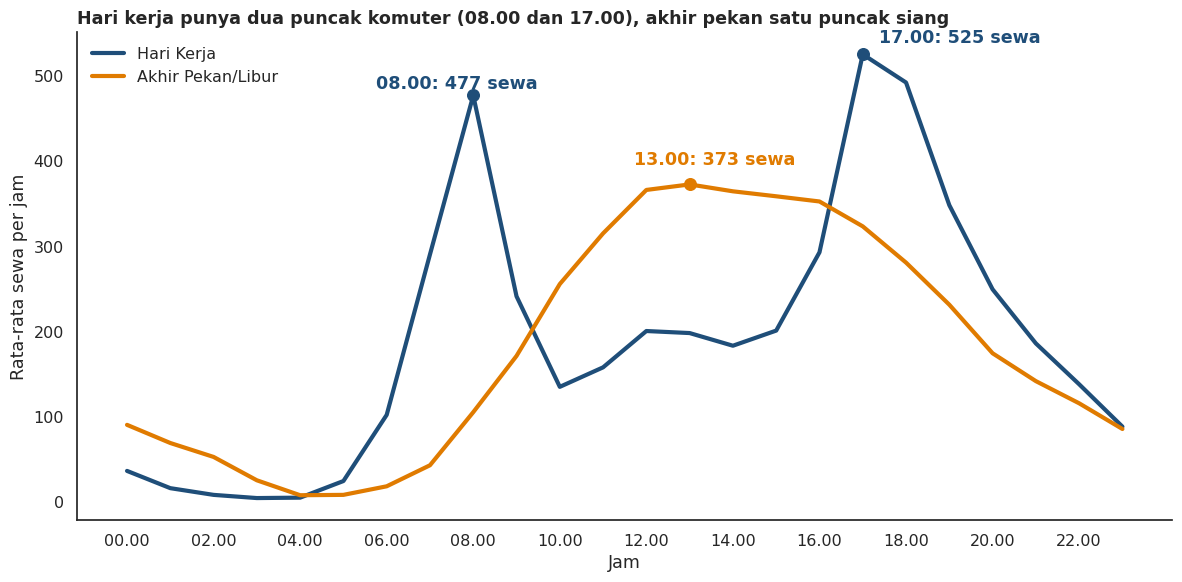

In [35]:
hourly_plot = hour_df.groupby(["hr", "day_type"])["cnt"].mean().reset_index()

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=hourly_plot, x="hr", y="cnt", hue="day_type", hue_order=day_type_order,
             palette=palette_day, linewidth=3, ax=ax)

annotations = [
    ("Hari Kerja", 8, (-70, 5)),
    ("Hari Kerja", 17, (12, 8)),
    ("Akhir Pekan/Libur", 13, (-40, 14)),
]
for day_type, hr, offset in annotations:
    value = hourly_plot.query("day_type == @day_type and hr == @hr")["cnt"].iloc[0]
    ax.scatter(hr, value, color=palette_day[day_type], s=70, zorder=3)
    ax.annotate(f"{hr:02d}.00: {value:.0f} sewa", (hr, value), textcoords="offset points",
                xytext=offset, color=palette_day[day_type], fontweight="bold")

ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels([f"{h:02d}.00" for h in range(0, 24, 2)])
ax.set_xlabel("Jam")
ax.set_ylabel("Rata-rata sewa per jam")
ax.set_title("Hari kerja punya dua puncak komuter (08.00 dan 17.00), akhir pekan satu puncak siang",
             loc="left", fontweight="bold")
ax.legend(title=None, frameon=False)
sns.despine()
plt.tight_layout()
plt.show()

**Insight:**
- Puncak tertinggi hari kerja ada pada jam 17.00 (525 sewa) dengan puncak pertama pada jam 08.00 (477 sewa), sedangkan akhir pekan/libur memuncak pada jam 13.00 (373 sewa).
- Pola dua puncak pada hari kerja konsisten dengan perjalanan berangkat dan pulang kerja, sedangkan pola satu puncak siang pada akhir pekan konsisten dengan penggunaan rekreasi.

### Pertanyaan 2: Berapa persen penurunan penyewaan pada tiap kondisi cuaca dan tiap musim?

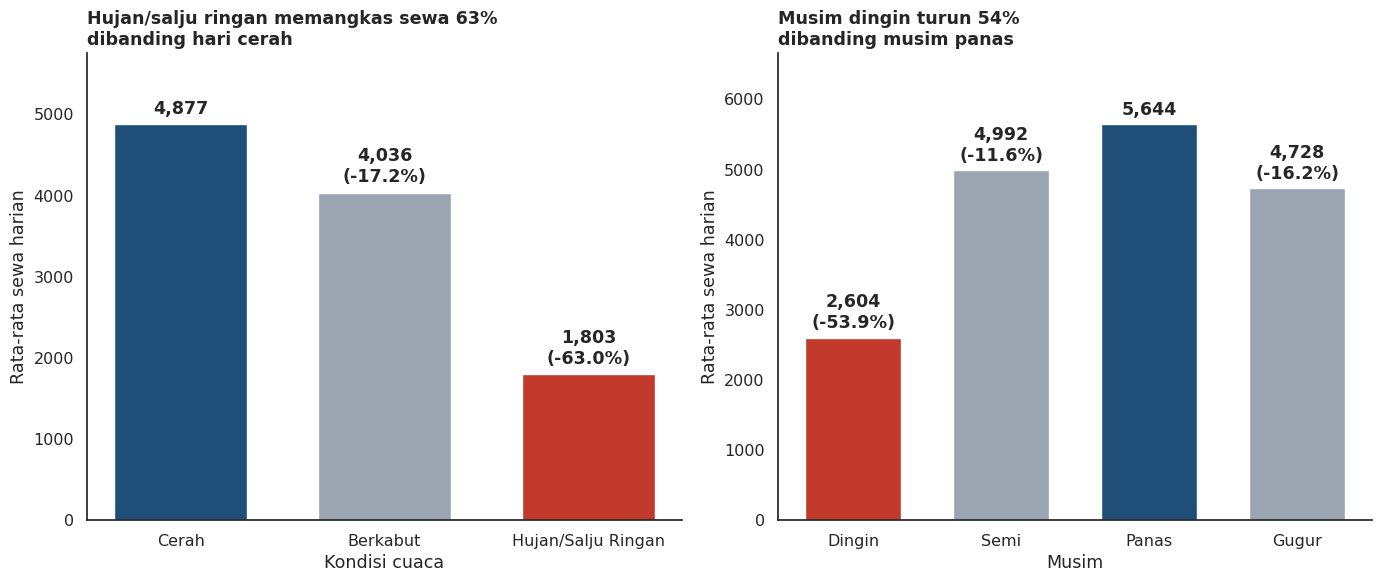

In [36]:
def plot_drop_bars(ax, summary, title, xlabel):
    values = summary["rata_rata_sewa"]
    baseline = values.idxmax()
    worst = values.idxmin()
    colors = ["#1f4e79" if name == baseline else "#c0392b" if name == worst else "#9aa5b1" for name in values.index]
    bars = ax.bar(values.index, values.values, color=colors, width=0.65)
    for bar, name in zip(bars, values.index):
        label = f"{values[name]:,.0f}"
        if name != baseline:
            label += f"\n(-{summary.loc[name, 'penurunan_pct']:.1f}%)"
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 80, label,
                ha="center", va="bottom", fontweight="bold")
    ax.set_ylim(0, values.max() * 1.18)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Rata-rata sewa harian")
    ax.set_title(title, loc="left", fontweight="bold")
    sns.despine(ax=ax)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_drop_bars(axes[0], weather_summary, "Hujan/salju ringan memangkas sewa 63%\ndibanding hari cerah", "Kondisi cuaca")
plot_drop_bars(axes[1], season_summary, "Musim dingin turun 54%\ndibanding musim panas", "Musim")
plt.tight_layout()
plt.show()

**Insight:**
- Cuaca: hari berkabut menurunkan sewa 17,2% dan hujan/salju ringan 63,0% dibandingkan hari cerah.
- Musim: Dingin turun 53,9%, Gugur 16,2%, dan Semi 11,6% dibandingkan musim Panas yang menjadi acuan.
- Dampak cuaca buruk jauh lebih besar daripada perbedaan antar musim hangat, sehingga prakiraan cuaca harian adalah faktor penting dalam perencanaan operasional.

### Pertanyaan 3: Berapa proporsi pengguna casual dan registered pada hari kerja dibandingkan akhir pekan/libur tiap bulan?

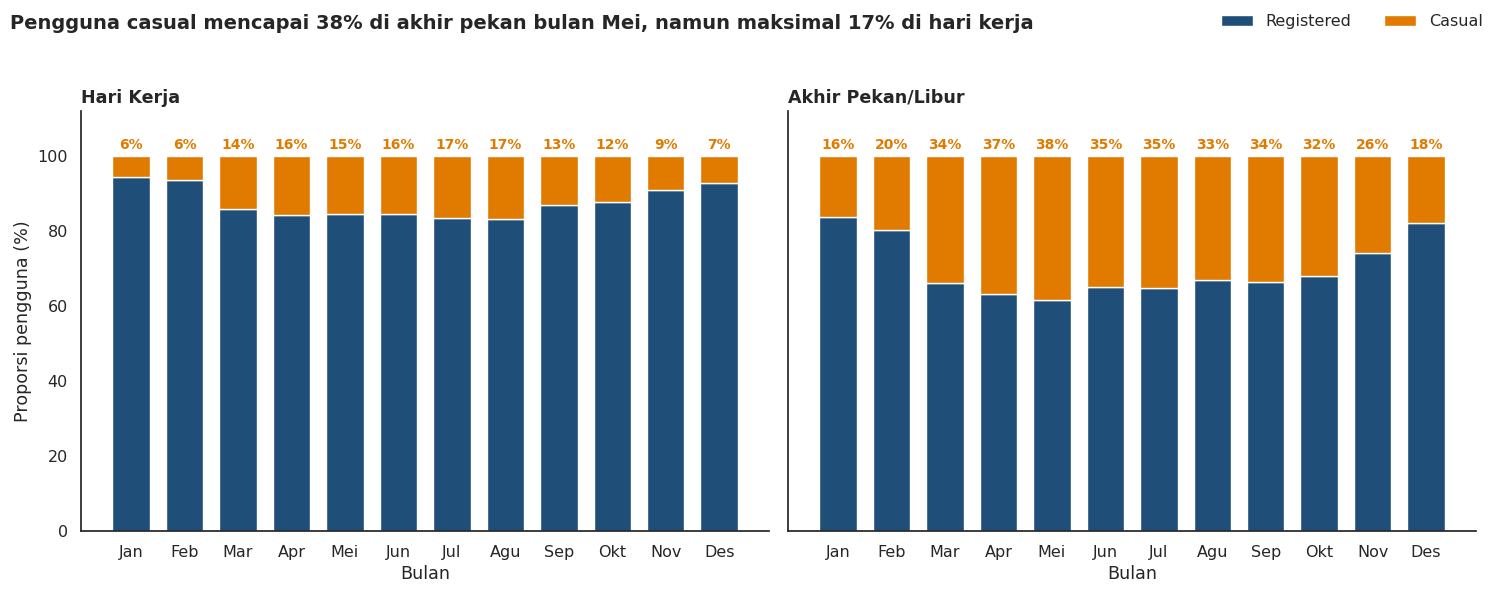

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
for ax, day_type in zip(axes, day_type_order):
    subset = monthly_users.xs(day_type, level="day_type").loc[month_order]
    registered_pct = 100 - subset["casual_pct"]
    ax.bar(month_order, registered_pct, color="#1f4e79", label="Registered", width=0.7)
    ax.bar(month_order, subset["casual_pct"], bottom=registered_pct, color="#e07b00", label="Casual", width=0.7)
    for i, value in enumerate(subset["casual_pct"]):
        ax.text(i, 102, f"{value:.0f}%", ha="center", color="#e07b00", fontweight="bold", fontsize=10)
    ax.set_ylim(0, 112)
    ax.set_title(day_type, loc="left", fontweight="bold")
    ax.set_xlabel("Bulan")
    sns.despine(ax=ax)
axes[0].set_ylabel("Proporsi pengguna (%)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False)
fig.suptitle("Pengguna casual mencapai 38% di akhir pekan bulan Mei, namun maksimal 17% di hari kerja",
             x=0.01, ha="left", fontweight="bold", fontsize=14)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Insight:**
- Porsi casual pada akhir pekan/libur selalu lebih tinggi daripada hari kerja di setiap bulan, dengan puncak 38% pada Mei dan titik terendah 16% pada Januari.
- Pada hari kerja porsi casual maksimal hanya 17% (Agustus), sehingga basis pengguna hari kerja didominasi registered.
- Bulan Maret sampai Oktober adalah periode dengan porsi casual akhir pekan di atas 30% dan menjadi peluang terbesar untuk konversi casual menjadi member.

## Conclusion & Recommendation
### Kesimpulan Pertanyaan 1: Jam puncak penyewaan hari kerja vs akhir pekan/libur
- Pada hari kerja, penyewaan memuncak dua kali: jam 08.00 (rata-rata 477 sewa) dan jam 17.00 (rata-rata 525 sewa, tertinggi). Pada akhir pekan/libur hanya ada satu puncak landai pada jam 13.00 (rata-rata 373 sewa).
- Hari kerja unggul paling jauh pada jam 08.00 (+371 sewa) dan jam 17.00-18.00 (+202 sampai +211 sewa). Akhir pekan/libur unggul pada jam 10.00-16.00, dengan selisih terbesar pada jam 14.00 (-181 untuk hari kerja).

### Kesimpulan Pertanyaan 2: Pengaruh cuaca dan musim terhadap penyewaan harian
- Dibandingkan hari cerah (rata-rata 4.877 sewa), hari berkabut turun 17,2% dan hari hujan/salju ringan turun 63,0%.
- Dibandingkan musim Panas (5.644 sewa), musim Dingin turun 53,9%, Gugur turun 16,2%, dan Semi turun 11,6%.
- Cuaca buruk dan musim dingin adalah dua penekan terbesar. Suhu yang hangat (di atas 20 C) berkaitan dengan sewa rata-rata di atas 5.500 per hari, sedangkan suhu di bawah 10 C hanya 1.678 per hari.

### Kesimpulan Pertanyaan 3: Proporsi pengguna casual dan registered
- Pengguna casual hanya 13,2% dari total sewa hari kerja, tetapi 31,7% pada akhir pekan/libur. Di setiap bulan, porsi casual akhir pekan/libur selalu lebih tinggi daripada hari kerja.
- Porsi casual akhir pekan/libur tertinggi pada Mei (38%) dan di atas 30% sepanjang Maret sampai Oktober, sedangkan porsi casual hari kerja paling tinggi hanya 17% (Juli dan Agustus).

### Rekomendasi (Action Item)
1. **Distribusi dan ketersediaan sepeda pada hari kerja.** Pastikan stok sepeda dan dok kosong tersedia sebelum jam 07.00 dan sebelum jam 16.00, lalu jadwalkan redistribusi dan perawatan di luar jam puncak (jam 10.00-15.00 dan malam hari). Pada akhir pekan/libur, geser stok ke jam 10.00-16.00.
2. **Penyesuaian operasional berbasis cuaca dan musim.** Gunakan prakiraan cuaca untuk menurunkan jumlah sepeda yang disebar saat diprediksi hujan, karena permintaan turun sekitar 63%, dan jadwalkan perawatan besar pada Desember sampai Februari saat permintaan terendah. Alihkan promo dan kampanye ke musim Semi sampai Gugur serta hari cerah.
3. **Konversi pengguna casual menjadi member.** Fokuskan promosi keanggotaan (misalnya diskon paket bulanan atau uji coba gratis) pada akhir pekan/libur bulan Maret sampai Oktober, saat porsi casual melampaui 30%.

### Catatan Keterbatasan
- Analisis bersifat deskriptif dan menunjukkan hubungan, bukan sebab-akibat.
- Data cuaca bersifat harian atau per jam tanpa lokasi stasiun, sehingga analisis spasial tidak dapat dilakukan.
- Rata-rata dihitung pada gabungan 2011-2012, sedangkan penyewaan 2012 jauh lebih tinggi daripada 2011.